# Laplace–Beltrami features in 3D

What each feature set measures, shown on reference shapes and on real TDSC-ABUS lesions. Theory and proofs are in [`lb-invariance.ipynb`](lb-invariance.ipynb) and [`lb-spectrum-content.ipynb`](lb-spectrum-content.ipynb). This notebook is the picture book. It makes no classification claims.

**The shapes.** A sphere and a bumpy sphere are the references. The lesions are Train cases at the 25th, 50th and 75th volume percentiles of each class, chosen by that rule rather than by appearance, so one malignant and one benign case do not show what separates the classes.

**Colour.** Signed values use blue and orange around grey; a value's sign has no meaning for eigenfunctions. Non-negative values use one blue ramp, darker meaning larger, clipped per panel to the 2nd–98th percentile and never narrower than ±30% of the median. Panels show pattern and cannot be compared by colour.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, matplotlib.pyplot as plt, trimesh
from matplotlib.colors import LinearSegmentedColormap
from abus_classification.features.shape_descriptor.shape_descriptors import (compute_eigendecomposition, compute_gps, compute_hks, compute_laplace_beltrami_operator, compute_wks)
from abus_classification.utils.mesh import draw_mesh
from test.utils_tests.features_tests.test_signature import SUNADA_LINES, SUNADA_POINTS, dimpled_sphere

BLUE, ORANGE, AQUA, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("signed", ["#104a8e", BLUE, "#dedcd6", ORANGE, "#8f3410"])
RAMP = LinearSegmentedColormap.from_list("ramp", ["#e6eef8", "#86b2e8", BLUE, "#104a8e"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
samples = np.load("../results/lb-spectrum-content/sample_meshes.npz")
def lesion(name, surface="smoothed"):
    return trimesh.Trimesh(samples[f"{name}_{surface}_vertices"].astype(float), samples[f"{name}_{surface}_faces"], process=False)
def bumpy():
    m = trimesh.creation.icosphere(subdivisions=5); rng = np.random.default_rng(3)
    centres = rng.normal(size=(14, 3)); centres /= np.linalg.norm(centres, axis=1, keepdims=True)
    r = 1 + 0.45 * np.exp((m.vertices @ centres.T - 1) / 0.012).sum(1)
    return trimesh.Trimesh(m.vertices * r[:, None], m.faces, process=False)
SHAPES = {"Sphere": trimesh.creation.icosphere(subdivisions=4), "Bumpy sphere": bumpy(), "Malignant lesion, median volume": lesion("malignant_q50"), "Benign lesion, median volume": lesion("benign_q50")}
def spectrum(m, k=300):
    L, M = compute_laplace_beltrami_operator(m); return compute_eigendecomposition(L, M, k=k)
SPECTRA = {name: spectrum(m) for name, m in SHAPES.items()}
def clip(v):  # at least +-30% of the median, so tiny mesh-level differences on a sphere are not stretched into a pattern
    middle = np.median(v); return dict(vmin=min(np.percentile(v, 2), 0.7 * middle), vmax=max(np.percentile(v, 98), 1.3 * middle))
def grid(columns, height=2.7, rows=SHAPES):
    fig = plt.figure(figsize=(2.5 * len(columns) + 0.3, height * len(rows)))
    return fig, [[fig.add_subplot(len(rows), len(columns), i * len(columns) + j + 1, projection="3d") for j in range(len(columns))] for i in range(len(rows))]
def label_rows(axes, names):
    for row, name in zip(axes, names): row[0].text2D(-0.05, 0.5, name, transform=row[0].transAxes, rotation=90, va="center", ha="center", fontsize=9, color=INK)

## 1. The real surfaces

Marching cubes on the binary mask gives a **staircase** surface whose steps are voxels, not anatomy. A small Gaussian smoothing (σ = 0.4 mm) gives the **smoothed** surface used below. Each panel has its own scale.

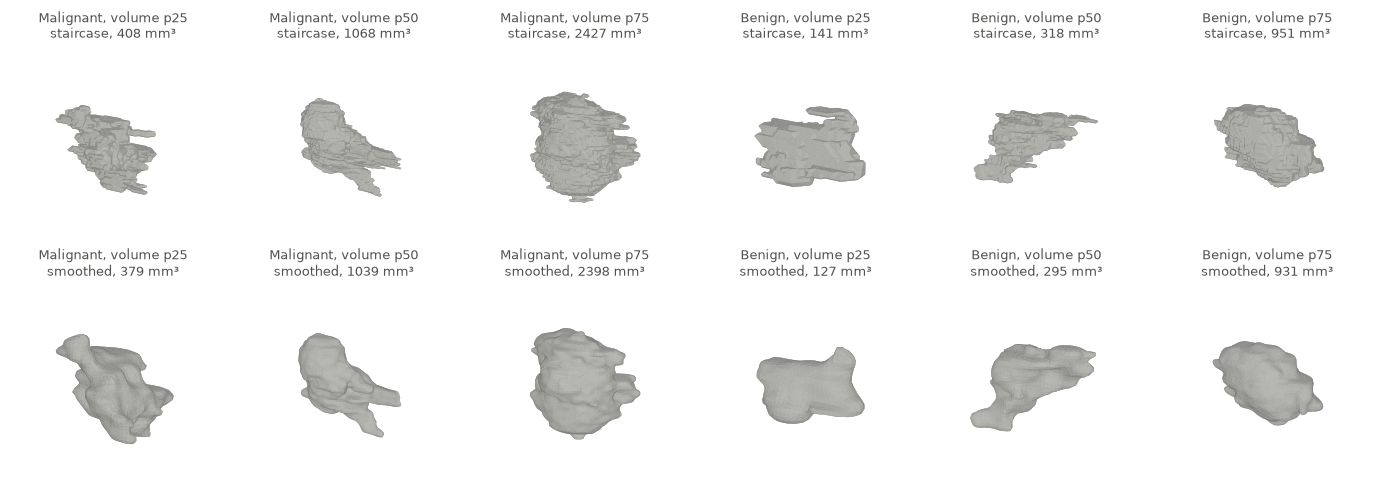

In [2]:
names = ["malignant_q25", "malignant_q50", "malignant_q75", "benign_q25", "benign_q50", "benign_q75"]
fig = plt.figure(figsize=(14, 5))
for i, name in enumerate(names):
    for row, surface in enumerate(("staircase", "smoothed")):
        ax = fig.add_subplot(2, 6, row * 6 + i + 1, projection="3d"); m = lesion(name, surface); draw_mesh(ax, m)
        cls, q = name.split("_q")
        ax.set_title(f"{cls.capitalize()}, volume p{q}\n{surface}, {abs(m.volume):.0f} mm³", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-lesions.png", dpi=130); plt.show()

## 2. Shape-DNA: the eigenvalues

**What it is.** The numbers $\lambda_0\le\lambda_1\le\dots$ of $-\Delta\phi=\lambda\phi$ on the surface: the squared pitches at which it would vibrate, one list per shape [Reuter et al. 2006].

**What it represents.** Global intrinsic geometry. Multiplied by area, the list ignores pose and size. Weyl's law says it grows along the line $4\pi k$, so all shapes look nearly alike on a plain plot. Shape shows up in the **departure from that line**, plotted below. The sphere's sawtooth comes from its multiplicities $2\\ell+1$; bumps and lobes break it up. One lesion per class shows no class difference.

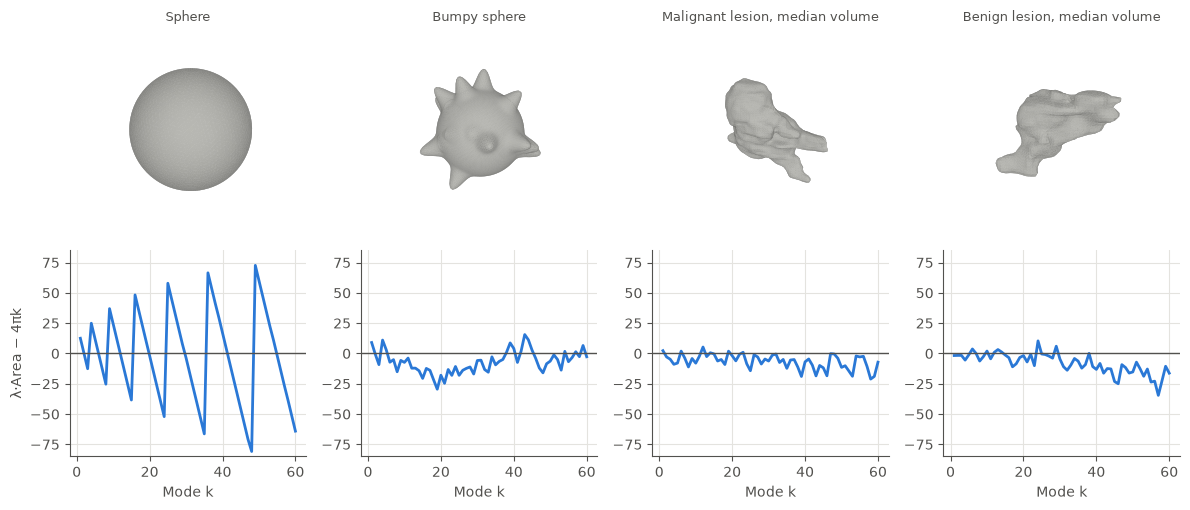

In [3]:
fig = plt.figure(figsize=(12, 5.2))
for i, (name, m) in enumerate(SHAPES.items()):
    ax = fig.add_subplot(2, 4, i + 1, projection="3d"); draw_mesh(ax, m); ax.set_title(name, fontsize=9, color=INK)
    ax = fig.add_subplot(2, 4, i + 5); lam = SPECTRA[name][0] * m.area; k = np.arange(1, 61)
    ax.plot(k, lam[1:61] - 4 * np.pi * k, color=BLUE, lw=2); ax.axhline(0, color=INK, lw=1)
    ax.set(xlabel="Mode k", ylim=(-85, 85)); ax.set_ylabel("λ·Area − 4πk" if i == 0 else "")
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-shapedna.png", dpi=130); plt.show()

## 3. Eigenfunctions: the vibration patterns

**What it is.** The function $\phi_k$ belonging to each eigenvalue. Colour shows $\phi_k$ on the surface.

**What it represents.** How the surface would vibrate. Low modes split a shape along its longest extents, higher modes make finer patches, and each is defined only up to sign. On a sphere, equal eigenvalues make the individual $\phi_k$ arbitrary within their group. On lesions, a mode's patches localise wherever the shape has room, such as lobes.

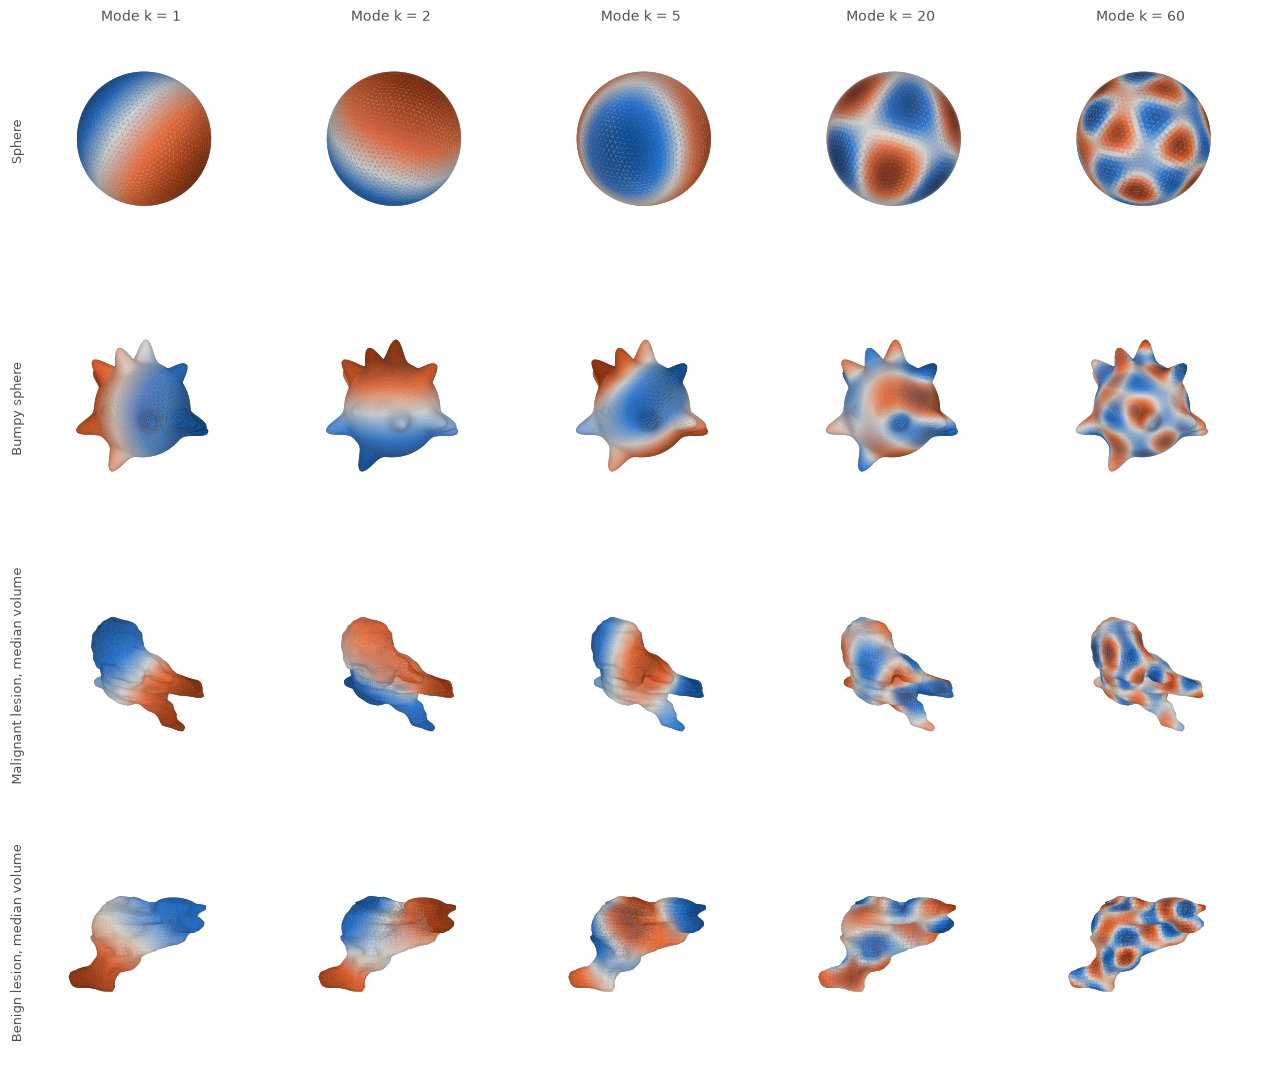

In [4]:
modes = [1, 2, 5, 20, 60]
fig, axes = grid(modes)
for row, (name, m) in zip(axes, SHAPES.items()):
    phi = SPECTRA[name][1]
    for ax, k in zip(row, modes):
        v = np.percentile(np.abs(phi[:, k]), 98); draw_mesh(ax, m, phi[:, k], DIVERGING, -v, v)
for ax, k in zip(axes[0], modes): ax.set_title(f"Mode k = {k}", fontsize=10, color=INK)
label_rows(axes, SHAPES); plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-modes.png", dpi=130); plt.show()

## 4. Heat diffusion and the heat trace

**What it is.** Put a point of heat at $x_0$ and let it spread: $u(x,t)=\sum_k e^{-\lambda_k t}\phi_k(x)\phi_k(x_0)$. The total of what returns to each starting point is the heat trace $Z(t)=\sum_k e^{-\lambda_k t}$.

**What it represents.** Time sets the distance explored. Very short times see area, then Euler number, then curvature, which is the expansion tested in `lb-spectrum-content.ipynb`. Times are written $\tau=t/\text{Area}$ so they mean the same thing on any lesion size.

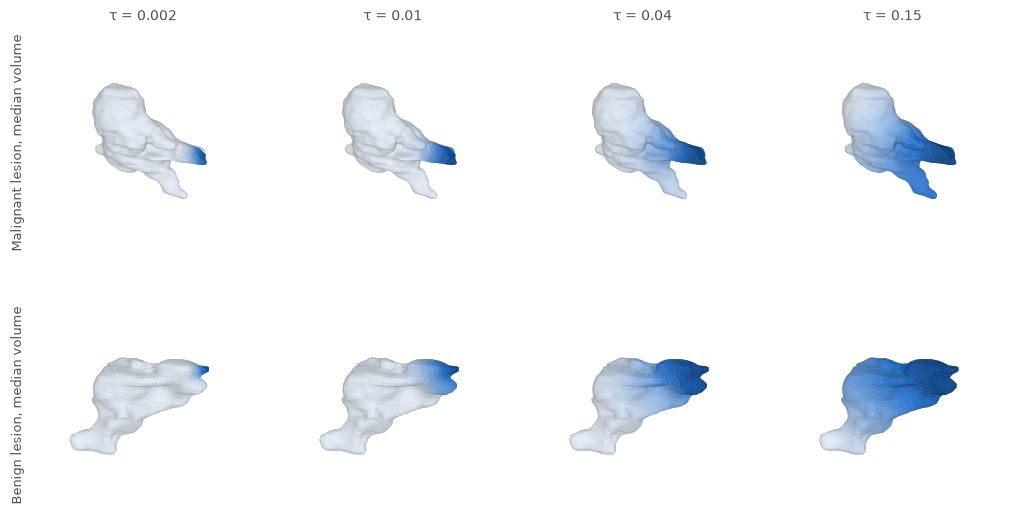

In [5]:
taus = [0.002, 0.01, 0.04, 0.15]; rows = {k: SHAPES[k] for k in list(SHAPES)[2:]}
fig, axes = grid(taus, rows=rows)
for row, (name, m) in zip(axes, rows.items()):
    lam, phi = SPECTRA[name]; x0 = int(np.argmax(m.vertices @ np.array([1.0, 0.3, 0.2])))
    for ax, tau in zip(row, taus):
        u = (np.exp(-lam * tau * m.area) * phi * phi[x0]).sum(1); draw_mesh(ax, m, u, RAMP, np.percentile(u, 2), u.max())
for ax, tau in zip(axes[0], taus): ax.set_title(f"τ = {tau}", fontsize=10, color=INK)
label_rows(axes, rows); plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-diffusion.png", dpi=130); plt.show()

## 5. Heat kernel signature (HKS)

**What it is.** $\text{HKS}(x,t)=\sum_k e^{-\lambda_k t}\phi_k(x)^2$: how much heat stays at $x$ after time $t$ [Sun et al. 2009]. One curve per surface point.

**What it represents.** Local shape at a scale set by $t$. Heat stays longer on tips, where it has little room to escape, and leaves faster from saddles and flats. So dark regions are protrusions, which is the closest thing here to a local "spike" detector: compare the bumpy sphere's tips. Long times show which whole lobes stand out. A sphere has no preferred point, so it stays flat.

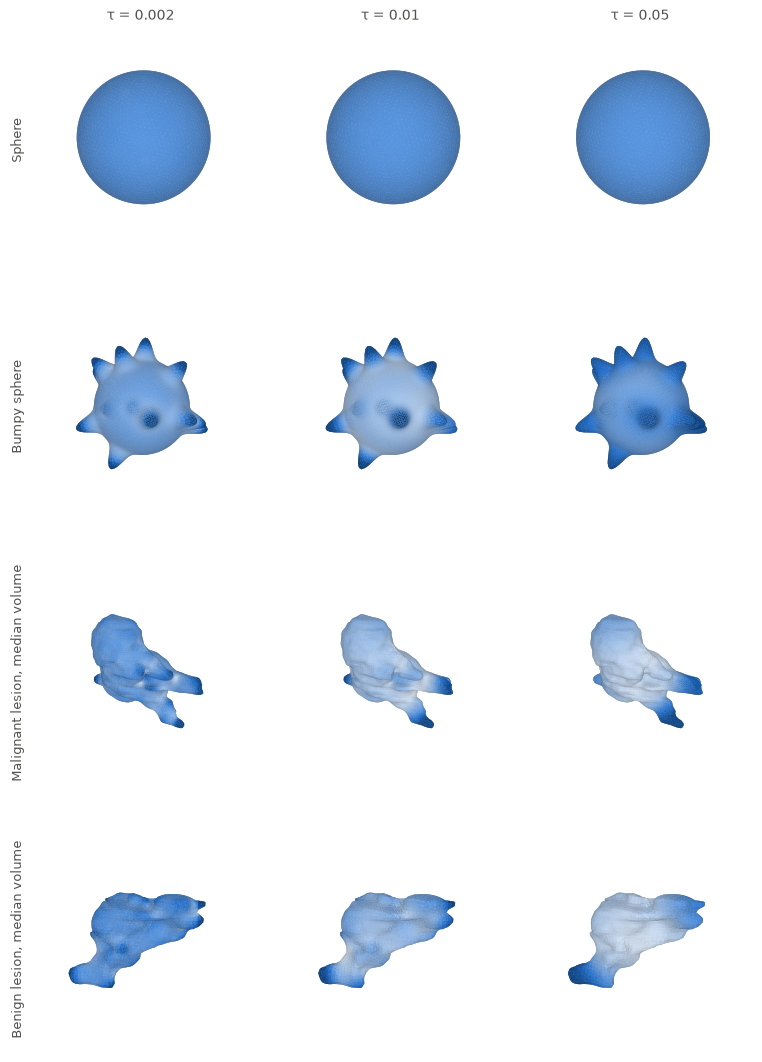

In [6]:
taus = [0.002, 0.01, 0.05]
fig, axes = grid(taus)
for row, (name, m) in zip(axes, SHAPES.items()):
    lam, phi = SPECTRA[name]; h = compute_hks(lam, phi, np.array(taus) * m.area)
    for ax, j in zip(row, range(3)): draw_mesh(ax, m, h[:, j], RAMP, **clip(h[:, j]))
for ax, tau in zip(axes[0], taus): ax.set_title(f"τ = {tau}", fontsize=10, color=INK)
label_rows(axes, SHAPES); plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-hks.png", dpi=130); plt.show()

## 6. Wave kernel signature (WKS)

**What it is.** The probability of finding a quantum particle at $x$, given its energy $e$: a Gaussian window over $\log\lambda$ picks the modes, and $\phi_k(x)^2$ is summed under it [Aubry et al. 2011].

**What it represents.** A band-pass view of the surface. Where HKS blurs everything below a scale, WKS isolates one frequency band, so it separates scales more sharply. Low energy shows the large parts, as HKS does. High energy shows ripples at the top of the 300 modes computed, so that panel depends on how many modes are used and is the least reliable.

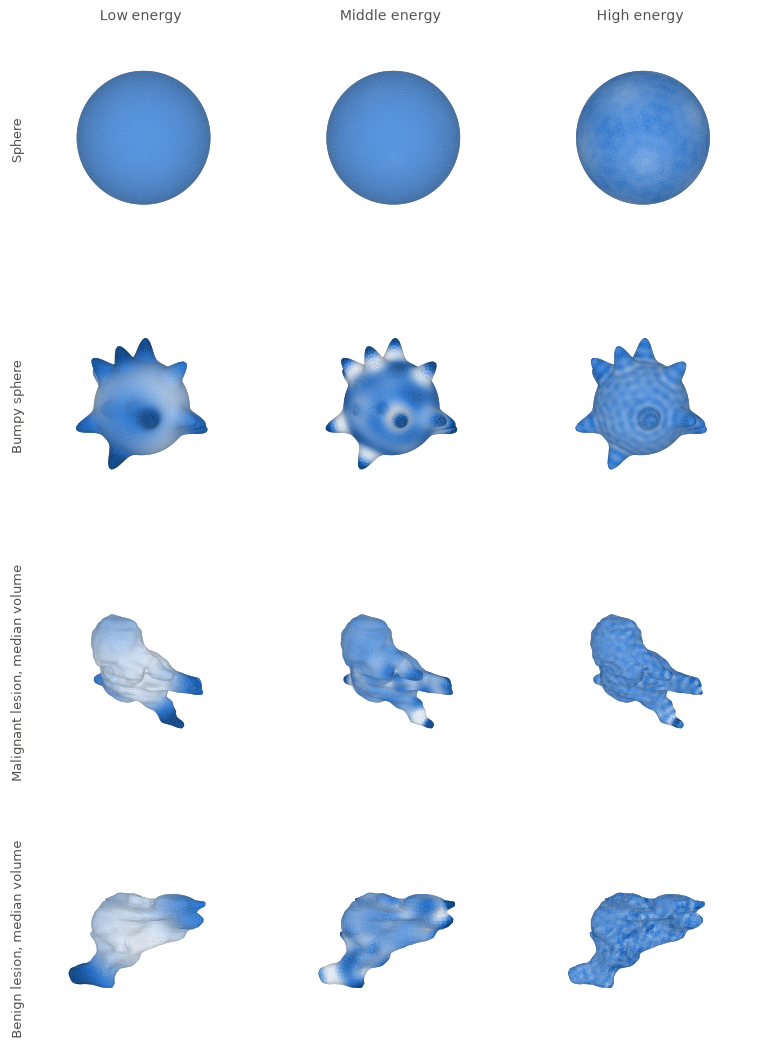

In [7]:
picks = [5, 50, 95]
fig, axes = grid(picks)
for row, (name, m) in zip(axes, SHAPES.items()):
    lam, phi = SPECTRA[name]; w = compute_wks(lam, phi)
    for ax, j in zip(row, picks): draw_mesh(ax, m, w[:, j], RAMP, **clip(w[:, j]))
for ax, t in zip(axes[0], ("Low energy", "Middle energy", "High energy")): ax.set_title(t, fontsize=10, color=INK)
label_rows(axes, SHAPES); plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-wks.png", dpi=130); plt.show()

## 7. Global point signature (GPS)

**What it is.** Each point gets the coordinates $\left(\phi_1/\sqrt{\lambda_1},\phi_2/\sqrt{\lambda_2},\dots\right)$ [Rustamov 2007].

**What it represents.** A new embedding of the surface in which distance reflects how the shape connects, not how it sits in space. Below, the same surface is redrawn at its first three GPS coordinates, with colour marking the original height so you can track points. Bending the surface leaves this embedding alone, apart from each axis's arbitrary sign. Long parts stretch out and small features collapse towards the middle.

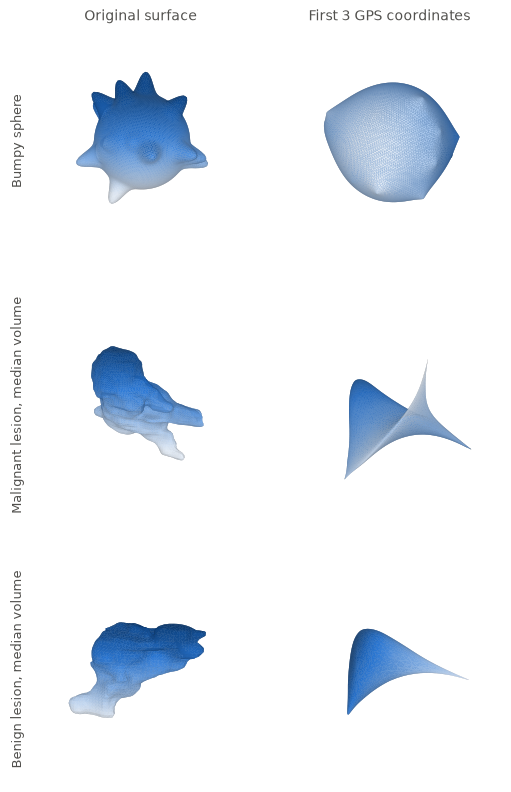

In [8]:
rows = {k: SHAPES[k] for k in list(SHAPES)[1:]}
fig, axes = grid(["a", "b"], rows=rows)
for row, (name, m) in zip(axes, rows.items()):
    lam, phi = SPECTRA[name]; g = compute_gps(lam, phi, 3); z = m.vertices[:, 2]
    draw_mesh(row[0], m, z, RAMP, **clip(z)); draw_mesh(row[1], trimesh.Trimesh(g, m.faces, process=False), z, RAMP, **clip(z))
axes[0][0].set_title("Original surface", fontsize=10, color=INK); axes[0][1].set_title("First 3 GPS coordinates", fontsize=10, color=INK)
label_rows(axes, rows); plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-gps.png", dpi=130); plt.show()

## 8. What the spectrum cannot see

**Same spectrum, different solid.** Mirroring a cap inward is an isometry, so the spectra match exactly while the volume does not. A spectrum alone cannot separate this dent from the original bulge.

**Same spectrum, different surface.** Sunada pairs are not isometric at all. Each graph below is one surface: nodes are 7 identical triangles, and a coloured edge glues two tiles along that side. A loop means the side joins the surface's second sheet. These surfaces are flat and abstract, so they are drawn as gluing patterns, not in 3D.

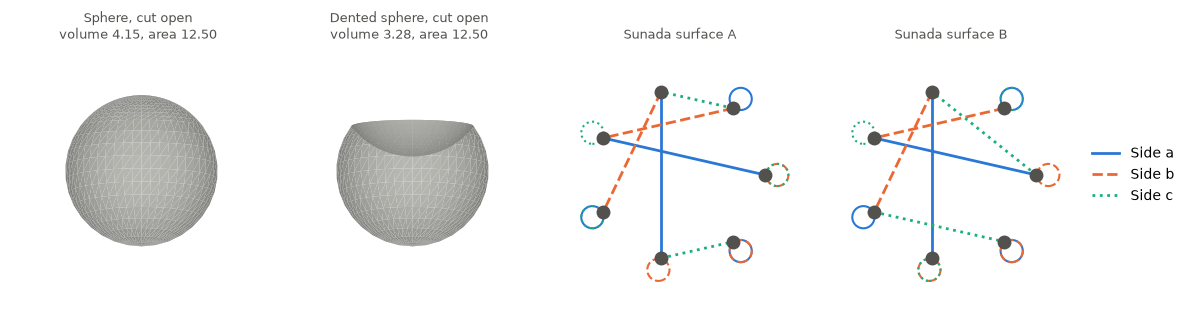

In [9]:
sphere, dented = dimpled_sphere(); fig = plt.figure(figsize=(12, 3.6))
for i, (m, name) in enumerate(((sphere, "Sphere"), (dented, "Dented sphere"))):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d"); slice_ = m.copy(); slice_.update_faces(m.vertices[m.faces].mean(1)[:, 1] > 0)
    draw_mesh(ax, slice_, view=(8, -90)); ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_title(f"{name}, cut open\nvolume {m.volume:.2f}, area {m.area:.2f}", fontsize=9, color=INK)
angle = 2 * np.pi * np.arange(7) / 7; xy = np.c_[np.cos(angle), np.sin(angle)]
for i, (gluing, name) in enumerate(((SUNADA_POINTS, "Sunada surface A"), (SUNADA_LINES, "Sunada surface B"))):
    ax = fig.add_subplot(1, 4, i + 3); ax.grid(False); ax.set_axis_off(); ax.set_aspect("equal"); ax.set_title(name, fontsize=9, color=INK)
    for perm, color, ls, side in zip(gluing, (BLUE, ORANGE, AQUA), ("-", "--", ":"), ("Side a", "Side b", "Side c")):
        for a, b in enumerate(perm):
            if a < b: ax.plot(*xy[[a, b]].T, color=color, ls=ls, lw=2)
            elif a == b: ax.add_patch(plt.Circle(xy[a] * 1.14, 0.13, fill=False, color=color, ls=ls, lw=1.5))
        ax.plot([], [], color=color, ls=ls, lw=2, label=side)
    ax.plot(*xy.T, "o", ms=9, color=INK); ax.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5))
    if i == 1: ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-limits.png", dpi=130); plt.show()